In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


In [5]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
original_df=pd.read_csv(r"C:\Users\HP\Documents\projects\home-credit-default-risk\application_train.csv")
original_df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df=pd.read_csv(r"C:\Users\HP\Documents\projects\home-credit-default-risk\application_train.csv")
df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [10]:
grt30=[]
lsr30=[]
for feature in df.columns:
    if ((df[feature].isnull().mean()*100)>30):
        grt30.append(feature)
    elif  (0.000<(df[feature].isnull().mean()*100)<30):
        lsr30.append(feature)
print(f"there are {len(grt30)} features that has missing values above 30%")
print(f"there are {len(lsr30)} features that has missing values below 30%")
grt30

there are 50 features that has missing values above 30%
there are 17 features that has missing values below 30%


['OWN_CAR_AGE',
 'OCCUPATION_TYPE',
 'EXT_SOURCE_1',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_AVG',
 'YEARS_BUILD_AVG',
 'COMMONAREA_AVG',
 'ELEVATORS_AVG',
 'ENTRANCES_AVG',
 'FLOORSMAX_AVG',
 'FLOORSMIN_AVG',
 'LANDAREA_AVG',
 'LIVINGAPARTMENTS_AVG',
 'LIVINGAREA_AVG',
 'NONLIVINGAPARTMENTS_AVG',
 'NONLIVINGAREA_AVG',
 'APARTMENTS_MODE',
 'BASEMENTAREA_MODE',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BUILD_MODE',
 'COMMONAREA_MODE',
 'ELEVATORS_MODE',
 'ENTRANCES_MODE',
 'FLOORSMAX_MODE',
 'FLOORSMIN_MODE',
 'LANDAREA_MODE',
 'LIVINGAPARTMENTS_MODE',
 'LIVINGAREA_MODE',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAREA_MODE',
 'APARTMENTS_MEDI',
 'BASEMENTAREA_MEDI',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'YEARS_BUILD_MEDI',
 'COMMONAREA_MEDI',
 'ELEVATORS_MEDI',
 'ENTRANCES_MEDI',
 'FLOORSMAX_MEDI',
 'FLOORSMIN_MEDI',
 'LANDAREA_MEDI',
 'LIVINGAPARTMENTS_MEDI',
 'LIVINGAREA_MEDI',
 'NONLIVINGAPARTMENTS_MEDI',
 'NONLIVINGAREA_MEDI',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MO

In [11]:
lsr30

['AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'CNT_FAM_MEMBERS',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'DAYS_LAST_PHONE_CHANGE',
 'AMT_REQ_CREDIT_BUREAU_HOUR',
 'AMT_REQ_CREDIT_BUREAU_DAY',
 'AMT_REQ_CREDIT_BUREAU_WEEK',
 'AMT_REQ_CREDIT_BUREAU_MON',
 'AMT_REQ_CREDIT_BUREAU_QRT',
 'AMT_REQ_CREDIT_BUREAU_YEAR']

In [12]:
ucat=[]
for feature in df.columns:
    if (df[feature].dtype =="O" and feature != "Target"):
        if len(df[feature].unique())==1:
            ucat.append(feature)
ucat

[]

In [13]:
unum=[]
for feature in df.columns:
    if (df[feature].dtype != "O"):
        if len(df[feature].unique())==1:
            unum.append(feature)
unum

[]

In [14]:
flag_doc_cols=[c for c in df.columns if c.startswith("FLAG_DOCUMENT")]
flag_cols_to_remove=[col for col in flag_doc_cols if (df[col]==0).mean()>=0.99]
print(flag_cols_to_remove)

['FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21']


In [15]:
remove=[col for col in flag_doc_cols if (df[col]==1).mean()>=0.99]
print(remove)

[]


In [16]:
flag_cols=[c for c in df.columns if c.startswith("FLAG")] #and c not in flag_cols_to_remove]
flag_cols_remove=[col for col in flag_cols if (df[col]==1).mean()>=0.99]
flag_cols_remove

['FLAG_MOBIL', 'FLAG_CONT_MOBILE']

In [17]:
remove_features=list(set(flag_cols_to_remove+grt30+flag_cols_remove))
len(remove_features)

68

In [18]:
df.drop("SK_ID_CURR",axis=1,inplace=True)
remove_features.append("SK_ID_CURR")

In [19]:
for feature in df.columns:
    if feature in remove_features:
        del df[feature]
print(f"the remaining columns after removal are {df.shape[1]}")


the remaining columns after removal are 53


In [20]:
df_desc=pd.read_csv(r"C:\Users\HP\Documents\projects\home-credit-default-risk\description.csv",encoding="latin1")
df_desc

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
...,...,...,...,...,...
214,217,installments_payments.csv,NUM_INSTALMENT_NUMBER,On which installment we observe payment,NaN
215,218,installments_payments.csv,DAYS_INSTALMENT,When the installment of previous credit was su...,time only relative to the application
216,219,installments_payments.csv,DAYS_ENTRY_PAYMENT,When was the installments of previous credit p...,time only relative to the application
217,220,installments_payments.csv,AMT_INSTALMENT,What was the prescribed installment amount of ...,NaN


In [21]:
x=df_desc[df_desc["Table"] == 'application_{train|test}.csv']
x

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
...,...,...,...,...,...
117,120,application_{train|test}.csv,AMT_REQ_CREDIT_BUREAU_DAY,Number of enquiries to Credit Bureau about the...,NaN
118,121,application_{train|test}.csv,AMT_REQ_CREDIT_BUREAU_WEEK,Number of enquiries to Credit Bureau about the...,NaN
119,122,application_{train|test}.csv,AMT_REQ_CREDIT_BUREAU_MON,Number of enquiries to Credit Bureau about the...,NaN
120,123,application_{train|test}.csv,AMT_REQ_CREDIT_BUREAU_QRT,Number of enquiries to Credit Bureau about the...,NaN


In [22]:
x=x[["Row","Description"]]
x

,Row,Description
0,SK_ID_CURR,ID of loan in our sample
1,TARGET,Target variable (1 - client with payment diffi...
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving
3,CODE_GENDER,Gender of the client
4,FLAG_OWN_CAR,Flag if the client owns a car
...,...,...
117,AMT_REQ_CREDIT_BUREAU_DAY,Number of enquiries to Credit Bureau about the...
118,AMT_REQ_CREDIT_BUREAU_WEEK,Number of enquiries to Credit Bureau about the...
119,AMT_REQ_CREDIT_BUREAU_MON,Number of enquiries to Credit Bureau about the...
120,AMT_REQ_CREDIT_BUREAU_QRT,Number of enquiries to Credit Bureau about the...


In [23]:
for feature in remove_features:
    x.drop(x[x["Row"] == feature].index,inplace=True)
x.reset_index(drop=True,inplace=True)
#x.drop(['level_0','index'],axis=1,inplace=True)
x

,Row,Description
0,TARGET,Target variable (1 - client with payment diffi...
1,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving
2,CODE_GENDER,Gender of the client
3,FLAG_OWN_CAR,Flag if the client owns a car
4,FLAG_OWN_REALTY,Flag if client owns a house or flat
5,CNT_CHILDREN,Number of children the client has
6,AMT_INCOME_TOTAL,Income of the client
7,AMT_CREDIT,Credit amount of the loan
8,AMT_ANNUITY,Loan annuity
9,AMT_GOODS_PRICE,For consumer loans it is the price of the good...


In [24]:
lsr30

['AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'CNT_FAM_MEMBERS',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'DAYS_LAST_PHONE_CHANGE',
 'AMT_REQ_CREDIT_BUREAU_HOUR',
 'AMT_REQ_CREDIT_BUREAU_DAY',
 'AMT_REQ_CREDIT_BUREAU_WEEK',
 'AMT_REQ_CREDIT_BUREAU_MON',
 'AMT_REQ_CREDIT_BUREAU_QRT',
 'AMT_REQ_CREDIT_BUREAU_YEAR']

In [25]:
null_col_des=x[x["Row"].isin(lsr30)]
null_col_des.reset_index(drop=True,inplace=True)
null_col_des

,Row,Description
0,AMT_ANNUITY,Loan annuity
1,AMT_GOODS_PRICE,For consumer loans it is the price of the good...
2,NAME_TYPE_SUITE,Who was accompanying client when he was applyi...
3,CNT_FAM_MEMBERS,How many family members does client have
4,EXT_SOURCE_2,Normalized score from external data source
5,EXT_SOURCE_3,Normalized score from external data source
6,OBS_30_CNT_SOCIAL_CIRCLE,How many observation of client's social surrou...
7,DEF_30_CNT_SOCIAL_CIRCLE,How many observation of client's social surrou...
8,OBS_60_CNT_SOCIAL_CIRCLE,How many observation of client's social surrou...
9,DEF_60_CNT_SOCIAL_CIRCLE,How many observation of client's social surrou...


In [26]:
for feature in lsr30:
    
    if df[feature].dtype !="O":
        
        if (abs(df[feature].skew())>1) :#and ((df[feature].isnull().sum()/len(df))*100)<0.05 :
            df[feature].fillna(df[feature].median(),inplace=True)
        elif(abs(df[feature].skew())<1): #and ((df[feature].isnull().sum()/len(df))*100)<0.05:
              df[feature].fillna(df[feature].mean(),inplace=True)
    if df[feature].dtype =="O":
        
        if ((df[feature].isnull().sum()/len(df))*100)<0.05:
            df[feature].fillna(df[feature].mode(),inplace=True)
        else:
            df[feature].fillna("Missing",inplace=True)
            
#numeric_cols=df.select_dtypes(include=["number"])
#continuous_cols=[col for col in numeric_cols.columns if not col.startswith(("FLAG_","REG_"))]
#skewed_features= df[continuous_cols].skew().abs().sort_values(ascending=False) 
#len(skewed_features)
#skewed_features

In [27]:
df.isnull().sum().sum()

np.int64(0)

In [28]:
len(lsr30)

17

In [29]:
numeric_cols=df.select_dtypes(include=["number"]).columns
continuous_cols=[col for col in numeric_cols if not col.startswith(("FLAG_","REG_"))]
skewed_features= df[continuous_cols].skew().abs().sort_values(ascending=False) 
print(len(skewed_features))
skewed_features

30


AMT_INCOME_TOTAL               391.559654
AMT_REQ_CREDIT_BUREAU_QRT      141.400915
AMT_REQ_CREDIT_BUREAU_DAY       29.081577
AMT_REQ_CREDIT_BUREAU_HOUR      15.641990
OBS_30_CNT_SOCIAL_CIRCLE        12.143796
OBS_60_CNT_SOCIAL_CIRCLE        12.075153
AMT_REQ_CREDIT_BUREAU_WEEK      10.008033
AMT_REQ_CREDIT_BUREAU_MON        8.371505
DEF_60_CNT_SOCIAL_CIRCLE         5.287339
DEF_30_CNT_SOCIAL_CIRCLE         5.192572
LIVE_REGION_NOT_WORK_REGION      4.651620
TARGET                           3.078159
CNT_CHILDREN                     1.974604
LIVE_CITY_NOT_WORK_CITY          1.669795
DAYS_EMPLOYED                    1.664346
AMT_ANNUITY                      1.579824
REGION_POPULATION_RELATIVE       1.488009
AMT_REQ_CREDIT_BUREAU_YEAR       1.465643
AMT_GOODS_PRICE                  1.350143
AMT_CREDIT                       1.234778
CNT_FAM_MEMBERS                  0.987546
EXT_SOURCE_2                     0.794429
DAYS_LAST_PHONE_CHANGE           0.713607
DAYS_REGISTRATION                0

In [30]:
skewed_features=skewed_features[skewed_features>1]
skewed_features=skewed_features.drop("TARGET")
print(len(skewed_features))
skewed_features

19


AMT_INCOME_TOTAL               391.559654
AMT_REQ_CREDIT_BUREAU_QRT      141.400915
AMT_REQ_CREDIT_BUREAU_DAY       29.081577
AMT_REQ_CREDIT_BUREAU_HOUR      15.641990
OBS_30_CNT_SOCIAL_CIRCLE        12.143796
OBS_60_CNT_SOCIAL_CIRCLE        12.075153
AMT_REQ_CREDIT_BUREAU_WEEK      10.008033
AMT_REQ_CREDIT_BUREAU_MON        8.371505
DEF_60_CNT_SOCIAL_CIRCLE         5.287339
DEF_30_CNT_SOCIAL_CIRCLE         5.192572
LIVE_REGION_NOT_WORK_REGION      4.651620
CNT_CHILDREN                     1.974604
LIVE_CITY_NOT_WORK_CITY          1.669795
DAYS_EMPLOYED                    1.664346
AMT_ANNUITY                      1.579824
REGION_POPULATION_RELATIVE       1.488009
AMT_REQ_CREDIT_BUREAU_YEAR       1.465643
AMT_GOODS_PRICE                  1.350143
AMT_CREDIT                       1.234778
dtype: float64

In [31]:
binary=[]
for col in skewed_features.index:
    if (df[col].nunique()<=2):
        binary.append(col)
        skewed_features.drop(col,inplace=True)
len(skewed_features)  

17

In [32]:
binary

['LIVE_REGION_NOT_WORK_REGION', 'LIVE_CITY_NOT_WORK_CITY']

In [33]:
numeric_cols=df.select_dtypes(include=["number"]).columns
encoded_cols= [col for col in numeric_cols if col.startswith(("FLAG_","REG_"))]
binary_cols=[col for col in encoded_cols if df[col].nunique() ==2]
binary_cols.extend(binary)
print(binary_cols)
len(binary_cols)

['FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8', 'LIVE_REGION_NOT_WORK_REGION', 'LIVE_CITY_NOT_WORK_CITY']


14

In [34]:
categorical_cols=df.select_dtypes(include=["object"]).columns
print(categorical_cols)
len(categorical_cols)

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START',
       'ORGANIZATION_TYPE'],
      dtype='object')


11

In [35]:
numeric_cols=df.select_dtypes(include=["number"]).columns
num_continuous_cols=[col for col in numeric_cols if not col.startswith(("FLAG_","REG_"))]
num_continuous_cols=[col for col in numeric_cols if col not in binary_cols]
num_continuous_cols.remove("TARGET")
len(num_continuous_cols)

27

In [36]:
df["CNT_CHILDREN"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          0.417052
std           0.722121
min           0.000000
50%           0.000000
90%           2.000000
95%           2.000000
99%           3.000000
99.9%         4.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [37]:
df["CNT_CHILDREN"].value_counts().sort_index()

CNT_CHILDREN
0     215371
1      61119
2      26749
3       3717
4        429
5         84
6         21
7          7
8          2
9          2
10         2
11         1
12         2
14         3
19         2
Name: count, dtype: int64

In [38]:
(df["CNT_CHILDREN"]>4).sum()

np.int64(126)

In [39]:
sus=df[df["CNT_CHILDREN"]>4]
sus

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_8,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
3079,0,Cash loans,M,N,Y,7,85500.0,411813.0,17577.0,355500.0,...,1,0,0,0,0.0,0.0,0.0,1.0,1.0,1.0
3448,0,Cash loans,F,N,Y,5,135000.0,579195.0,24669.0,468000.0,...,1,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
7204,0,Cash loans,M,N,N,6,157500.0,566055.0,16551.0,472500.0,...,1,0,0,0,0.0,0.0,0.0,0.0,1.0,3.0
8254,0,Cash loans,M,Y,N,5,270000.0,840951.0,35761.5,679500.0,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
9712,1,Cash loans,F,N,Y,5,162000.0,704844.0,34038.0,630000.0,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
291909,0,Cash loans,M,N,Y,5,202500.0,1317357.0,52375.5,1129500.0,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
296798,1,Cash loans,F,N,Y,5,198000.0,227520.0,15201.0,180000.0,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
300538,1,Cash loans,F,N,Y,5,36000.0,351000.0,17199.0,351000.0,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
305112,0,Cash loans,F,N,N,7,112500.0,143910.0,15399.0,135000.0,...,1,0,0,0,0.0,0.0,1.0,0.0,0.0,2.0


In [40]:
sus[["CNT_CHILDREN","CNT_FAM_MEMBERS"]]

,CNT_CHILDREN,CNT_FAM_MEMBERS
3079,7,9.0
3448,5,7.0
7204,6,8.0
8254,5,7.0
9712,5,7.0
...,...,...
291909,5,7.0
296798,5,7.0
300538,5,7.0
305112,7,8.0


In [41]:
sus[sus["CNT_FAM_MEMBERS"]<sus["CNT_CHILDREN"]]

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_8,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


In [42]:
df["AMT_INCOME_TOTAL"].sort_values(ascending=False).head(20)

12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0
103006      4500000.0
204564      4500000.0
187833      4500000.0
287463      4500000.0
181698      3950059.5
20216       3825000.0
284311      3600000.0
49645       3600000.0
82846       3375000.0
86026       3375000.0
101007      3150000.0
248159      3150000.0
107926      2930026.5
258773      2700000.0
298082      2475000.0
Name: AMT_INCOME_TOTAL, dtype: float64

In [43]:
df["AMT_INCOME_TOTAL"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
50%      1.471500e+05
90%      2.700000e+05
95%      3.375000e+05
99%      4.725000e+05
99.9%    9.000000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [44]:
(df["AMT_INCOME_TOTAL"]>9000000).sum()

np.int64(3)

In [45]:
df["AMT_REQ_CREDIT_BUREAU_QRT"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          0.229631
std           0.744059
min           0.000000
50%           0.000000
90%           1.000000
95%           2.000000
99%           2.000000
99.9%         4.000000
max         261.000000
Name: AMT_REQ_CREDIT_BUREAU_QRT, dtype: float64

In [46]:
(df["AMT_REQ_CREDIT_BUREAU_QRT"]>4).sum()

np.int64(108)

In [47]:
temp=df[df["AMT_REQ_CREDIT_BUREAU_QRT"]>4]

In [48]:
temp[["AMT_REQ_CREDIT_BUREAU_QRT","TARGET"]]

,AMT_REQ_CREDIT_BUREAU_QRT,TARGET
3770,8.0,0
4471,5.0,0
5985,6.0,1
11326,7.0,0
15427,6.0,0
...,...,...
286191,6.0,0
289714,8.0,0
298298,5.0,0
298421,5.0,0


In [49]:
temp["AMT_REQ_CREDIT_BUREAU_QRT"].value_counts()

AMT_REQ_CREDIT_BUREAU_QRT
5.0      64
6.0      28
8.0       7
7.0       7
261.0     1
19.0      1
Name: count, dtype: int64

In [50]:
temp[temp["AMT_REQ_CREDIT_BUREAU_QRT"]>100]

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_8,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
239474,0,Cash loans,F,N,Y,1,360000.0,1035000.0,30393.0,1035000.0,...,1,0,0,0,0.0,0.0,0.0,1.0,261.0,0.0


In [51]:
original_df.loc[239474,["AMT_REQ_CREDIT_BUREAU_QRT",
                       "AMT_REQ_CREDIT_BUREAU_YEAR",
                       "AMT_REQ_CREDIT_BUREAU_MON",
                       "AMT_REQ_CREDIT_BUREAU_DAY",
                       "AMT_REQ_CREDIT_BUREAU_WEEK"]]
    

AMT_REQ_CREDIT_BUREAU_QRT     261.0
AMT_REQ_CREDIT_BUREAU_YEAR      0.0
AMT_REQ_CREDIT_BUREAU_MON       1.0
AMT_REQ_CREDIT_BUREAU_DAY       0.0
AMT_REQ_CREDIT_BUREAU_WEEK      0.0
Name: 239474, dtype: object

In [52]:
inconsistent=original_df[original_df["AMT_REQ_CREDIT_BUREAU_QRT"]>original_df["AMT_REQ_CREDIT_BUREAU_YEAR"]]

In [53]:
original_df["AMT_REQ_CREDIT_BUREAU_QRT"].max()

261.0

In [54]:
inconsistent[["AMT_REQ_CREDIT_BUREAU_QRT","AMT_REQ_CREDIT_BUREAU_YEAR"]].value_counts()


AMT_REQ_CREDIT_BUREAU_QRT  AMT_REQ_CREDIT_BUREAU_YEAR
1.0                        0.0                           7094
2.0                        1.0                           2981
                           0.0                           2563
3.0                        1.0                            324
                           2.0                            312
                           0.0                            227
4.0                        3.0                             83
                           1.0                             83
                           2.0                             76
                           0.0                             61
5.0                        4.0                             11
                           1.0                             10
                           2.0                              9
                           3.0                              9
6.0                        3.0                              7
5.0             

In [55]:
df.groupby("AMT_REQ_CREDIT_BUREAU_QRT")["TARGET"].mean()

AMT_REQ_CREDIT_BUREAU_QRT
0.0      0.082499
1.0      0.065767
2.0      0.083472
3.0      0.073384
4.0      0.119748
5.0      0.093750
6.0      0.250000
7.0      0.142857
8.0      0.000000
19.0     1.000000
261.0    0.000000
Name: TARGET, dtype: float64

In [56]:
df.select_dtypes(include=["object"]).columns

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START',
       'ORGANIZATION_TYPE'],
      dtype='object')

In [57]:
df["AMT_REQ_CREDIT_BUREAU_DAY"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          0.006055
std           0.103037
min           0.000000
50%           0.000000
90%           0.000000
95%           0.000000
99%           0.000000
99.9%         1.000000
max           9.000000
Name: AMT_REQ_CREDIT_BUREAU_DAY, dtype: float64

In [58]:
(df["AMT_REQ_CREDIT_BUREAU_DAY"]>1).sum()

np.int64(197)

In [59]:
df["AMT_REQ_CREDIT_BUREAU_HOUR"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          0.005538
std           0.078014
min           0.000000
50%           0.000000
90%           0.000000
95%           0.000000
99%           0.000000
99.9%         1.000000
max           4.000000
Name: AMT_REQ_CREDIT_BUREAU_HOUR, dtype: float64

In [60]:
(df["AMT_REQ_CREDIT_BUREAU_HOUR"]>1).sum()

np.int64(66)

In [61]:
df["AMT_REQ_CREDIT_BUREAU_WEEK"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          0.029723
std           0.190728
min           0.000000
50%           0.000000
90%           0.000000
95%           0.000000
99%           1.000000
99.9%         2.000000
max           8.000000
Name: AMT_REQ_CREDIT_BUREAU_WEEK, dtype: float64

In [62]:
(df["AMT_REQ_CREDIT_BUREAU_WEEK"]>2).sum()

np.int64(129)

In [63]:
df["OBS_30_CNT_SOCIAL_CIRCLE"].unique()

array([  2.,   1.,   0.,   4.,   8.,  10.,   7.,   3.,   6.,   5.,  12.,
         9.,  13.,  11.,  14.,  22.,  16.,  15.,  17.,  20.,  25.,  19.,
        18.,  21.,  24.,  23.,  28.,  26.,  29.,  27.,  47., 348.,  30.])

In [64]:
df["OBS_30_CNT_SOCIAL_CIRCLE"].describe(percentiles=[0.90,0.95,0.99,0.999])

count    307511.000000
mean          1.417523
std           2.398395
min           0.000000
50%           0.000000
90%           4.000000
95%           6.000000
99%          10.000000
99.9%        17.000000
max         348.000000
Name: OBS_30_CNT_SOCIAL_CIRCLE, dtype: float64

In [65]:
ob_sus=df[df["OBS_30_CNT_SOCIAL_CIRCLE"]>17]
ob_sus[["OBS_30_CNT_SOCIAL_CIRCLE","OBS_60_CNT_SOCIAL_CIRCLE","DEF_30_CNT_SOCIAL_CIRCLE","DEF_60_CNT_SOCIAL_CIRCLE"]]

,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE
1396,22.0,21.0,1.0,1.0
3004,22.0,22.0,0.0,0.0
5281,20.0,20.0,0.0,0.0
7159,25.0,25.0,0.0,0.0
9330,19.0,19.0,0.0,0.0
...,...,...,...,...
296762,20.0,19.0,0.0,0.0
298178,18.0,18.0,0.0,0.0
299614,20.0,20.0,0.0,0.0
302894,25.0,25.0,0.0,0.0


In [66]:
ob_sus[ob_sus["OBS_30_CNT_SOCIAL_CIRCLE"]<ob_sus["OBS_60_CNT_SOCIAL_CIRCLE"]]


,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_8,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


In [67]:
ob_sus[ob_sus["DEF_30_CNT_SOCIAL_CIRCLE"]<ob_sus["DEF_60_CNT_SOCIAL_CIRCLE"]]


,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_8,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


In [68]:
df.select_dtypes(include=["object"]).columns.tolist()

['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE']

In [69]:
df['NAME_INCOME_TYPE'].unique().tolist()

['Working',
 'State servant',
 'Commercial associate',
 'Pensioner',
 'Unemployed',
 'Student',
 'Businessman',
 'Maternity leave']

In [70]:
binary

['LIVE_REGION_NOT_WORK_REGION', 'LIVE_CITY_NOT_WORK_CITY']

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
from sklearn.preprocessing import StandardScaler

In [72]:
onehot_cols=['NAME_CONTRACT_TYPE',
             'CODE_GENDER',
             'FLAG_OWN_CAR',
             'FLAG_OWN_REALTY',
             'NAME_INCOME_TYPE',
             "NAME_TYPE_SUITE",
             "NAME_FAMILY_STATUS",
             "NAME_HOUSING_TYPE",
             "WEEKDAY_APPR_PROCESS_START",
             "ORGANIZATION_TYPE"
             ]

In [73]:
ordinal_cols=['NAME_EDUCATION_TYPE']

In [74]:
ordinal_pipeline=Pipeline([
                         ("ordinal",OrdinalEncoder(categories=[['Lower secondary',
                                                                'Secondary / secondary special',
                                                                'Incomplete higher',
                                                                'Higher education',
                                                                'Academic degree']]))
                         ])

In [75]:
onehot_pipeline=Pipeline([
    ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore"))
])

### for linear_models scaling for numeric columns is required 

In [76]:
numerical_cols=num_continuous_cols
len(numerical_cols)

27

In [77]:
print(categorical_cols)
len(categorical_cols)

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START',
       'ORGANIZATION_TYPE'],
      dtype='object')


11

In [78]:
binary_cols
len(binary_cols)

14

In [79]:
numeric_pipeline=Pipeline([("scaler",StandardScaler())])

In [80]:
scaled_preprocessor=ColumnTransformer([
    ("num",numeric_pipeline,numerical_cols),
    ("binary","passthrough",binary_cols),
    ("ordinal",ordinal_pipeline,ordinal_cols),
    ("onehot",onehot_pipeline,onehot_cols)],remainder="passthrough")

In [81]:
from sklearn.model_selection import train_test_split

In [82]:
X=df.drop(["TARGET"],axis=1)
Y=df["TARGET"]
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.3,random_state=42,stratify=Y)

In [83]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(215257, 52)
(92254, 52)
(215257,)
(92254,)


In [84]:
x_train,x_val,y_train,y_val=train_test_split(x_train,y_train,test_size=0.20,random_state=42,stratify=y_train)

In [85]:
print(x_train.shape)
print(x_val.shape)
print(y_train.shape)
print(y_val.shape)

(172205, 52)
(43052, 52)
(172205,)
(43052,)


In [86]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
log_pipeline=Pipeline([
    ("preprocessor",scaled_preprocessor),
    ("smote",SMOTE(random_state=42)),
    ("model",LogisticRegression(class_weight="balanced"))
])     

In [87]:

log_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('binary', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [88]:
from sklearn.ensemble import RandomForestClassifier,VotingClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from sklearn.ensemble import VotingClassifier

In [89]:
preprocessor=ColumnTransformer(transformers=[("binary","passthrough",binary_cols),
                                             ("ordinal",ordinal_pipeline,ordinal_cols),
                                             ("onehot",onehot_pipeline,onehot_cols)],remainder="passthrough")

In [90]:
svm_pipeline=Pipeline([
     ("preprocessor",scaled_preprocessor),
     ("smote",SMOTE(random_state=42)),
     ("model",LinearSVC())
])
svm_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('binary', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [91]:
rf_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ('smote', SMOTE(random_state=42)),
    ("model",RandomForestClassifier(n_estimators=200,random_state=42,class_weight="balanced",n_jobs=-1))
])
rf_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('binary', ...), ('ordinal', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [92]:
xgb_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ('smote', SMOTE(random_state=42)),
    ("model",XGBClassifier(n_estimators=300,random_state=42,class_weight="balanced",eval_metric="logloss"))
    ])
xgb_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('binary', ...), ('ordinal', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [94]:
voting=VotingClassifier(estimators=[
                                ("log",log_pipeline),
                                ('rf', rf_pipeline), 
                                ('svm', svm_pipeline), 
                                ('xgb', xgb_pipeline)],voting="hard")
                           
voting_pipeline = Pipeline([
                            ("model",voting)])


voting_pipeline.fit(x_train, y_train)

,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,estimators,"[('log', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,transformers,"[('num', ...), ('binary', ...), ...]"


In [95]:
from sklearn.metrics import accuracy_score,classification_report

In [96]:
model_pipelines = {
"logistic": log_pipeline,   
"Random Forest": rf_pipeline,
"Svm": svm_pipeline,
"XGBoost": xgb_pipeline,
"Voting": voting
}
for name, model in model_pipelines.items():
    y_pred = model.predict(x_test)
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))


 logistic
Accuracy: 0.6912003815552713
              precision    recall  f1-score   support

           0       0.96      0.69      0.81     84806
           1       0.16      0.65      0.25      7448

    accuracy                           0.69     92254
   macro avg       0.56      0.67      0.53     92254
weighted avg       0.89      0.69      0.76     92254


 Random Forest
Accuracy: 0.9192772129121772
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84806
           1       0.67      0.00      0.00      7448

    accuracy                           0.92     92254
   macro avg       0.79      0.50      0.48     92254
weighted avg       0.90      0.92      0.88     92254


 Svm
Accuracy: 0.6911570230017127
              precision    recall  f1-score   support

           0       0.96      0.70      0.81     84806
           1       0.16      0.65      0.25      7448

    accuracy                           0.69     92254
   macro

In [97]:
from sklearn.metrics import classification_report
y_prob=log_pipeline.predict_proba(x_test)[:,1]
for threshold in [0.5,0.4,0.3,0.2,0.1]:
    y_pred=(y_prob>=threshold).astype(int)
    print(f"threshold: {threshold}")
    print(classification_report(y_test,y_pred))

threshold: 0.5
              precision    recall  f1-score   support

           0       0.96      0.69      0.81     84806
           1       0.16      0.65      0.25      7448

    accuracy                           0.69     92254
   macro avg       0.56      0.67      0.53     92254
weighted avg       0.89      0.69      0.76     92254

threshold: 0.4
              precision    recall  f1-score   support

           0       0.97      0.55      0.70     84806
           1       0.13      0.78      0.22      7448

    accuracy                           0.57     92254
   macro avg       0.55      0.66      0.46     92254
weighted avg       0.90      0.57      0.66     92254

threshold: 0.3
              precision    recall  f1-score   support

           0       0.97      0.38      0.55     84806
           1       0.11      0.88      0.20      7448

    accuracy                           0.42     92254
   macro avg       0.54      0.63      0.37     92254
weighted avg       0.90      

In [98]:
from sklearn.metrics import classification_report
y_prob=svm_pipeline.decision_function(x_test)
for threshold in [0.5,0.4,0.3,0.2,0.1]:
    y_pred=(y_prob>=threshold).astype(int)
    print(f"threshold: {threshold}")
    print(classification_report(y_test,y_pred))

threshold: 0.5
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     84806
           1       0.28      0.24      0.26      7448

    accuracy                           0.89     92254
   macro avg       0.61      0.59      0.60     92254
weighted avg       0.88      0.89      0.89     92254

threshold: 0.4
              precision    recall  f1-score   support

           0       0.94      0.92      0.93     84806
           1       0.25      0.31      0.28      7448

    accuracy                           0.87     92254
   macro avg       0.60      0.62      0.61     92254
weighted avg       0.88      0.87      0.88     92254

threshold: 0.3
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     84806
           1       0.22      0.39      0.29      7448

    accuracy                           0.84     92254
   macro avg       0.58      0.64      0.60     92254
weighted avg       0.88      

In [99]:
from sklearn.metrics import classification_report
y_prob=log_pipeline.predict_proba(x_test)[:,1]
y_pred=(y_prob>=0.3).astype(int)
print(f"threshold: {threshold}")
print(classification_report(y_test,y_pred))

threshold: 0.1
              precision    recall  f1-score   support

           0       0.97      0.38      0.55     84806
           1       0.11      0.88      0.20      7448

    accuracy                           0.42     92254
   macro avg       0.54      0.63      0.37     92254
weighted avg       0.90      0.42      0.52     92254



In [100]:
from sklearn.metrics import (
confusion_matrix,
ConfusionMatrixDisplay,
roc_curve,roc_auc_score)

In [101]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[32384 52422]
 [  895  6553]]


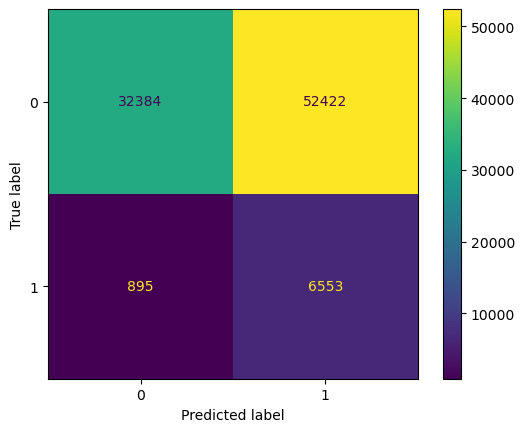

In [102]:
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.show()

In [105]:
fpr,tpr,thresholds=roc_curve(y_test,y_prob)
auc_score=roc_auc_score(y_test,y_prob)

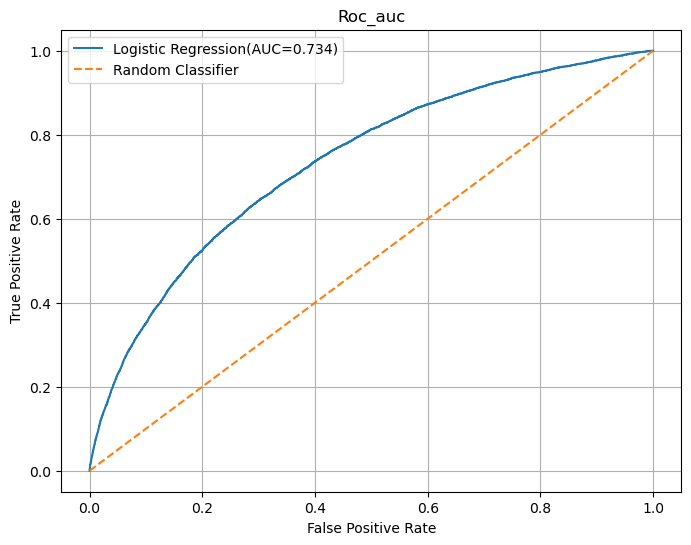

In [106]:
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,label=f"Logistic Regression(AUC={auc_score:.3f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Roc_auc")
plt.legend()
plt.grid(True)
plt.show()

